# Week 3 Task 1: Model Experimentation, Tuning & MLflow Tracking
**Project:** Telco Customer Churn Prediction & Retention Optimization  
**Deliverables:**
1. Tree ensembles: Random Forest, XGBoost, and LightGBM
2. Stratified 5-Fold Cross-Validation on imbalanced data
3. Bayesian Hyperparameter Tuning with Optuna
4. Experiment logging to MLflow (`sqlite:///mlflow.db`)
5. Model Leaderboard and Champion Model selection with rationale


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import optuna

from src.features import prepare_train_test_data
from src.train import (
    run_stratified_cv,
    evaluate_model_performance,
    tune_xgboost,
    tune_lightgbm,
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# Setup MLflow tracking
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("telco_churn_experimentation")


C:\Users\kjuge\Documents\jugendrakashyap\AI-ML-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/24 03:51:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\kjuge\Documents\jugendrakashyap\AI-ML-Project\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/24 03:51:40 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/24 03:51:40 INFO mlflow.store.db.utils: Updating database tables


2026/10/24 03:51:42 INFO mlflow.tracking.fluent: Experiment with name 'telco_churn_experimentation' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:C:/Users/kjuge/Documents/jugendrakashyap/AI-ML-Project/mlruns/1', creation_time=1792792921570, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792792921570, lifecycle_stage='active', name='telco_churn_experimentation', tags={}, trace_location=None, workspace='default'>

## 1. Feature Data Ingestion
Loading prepared features and verifying dimensions.


In [2]:
data = prepare_train_test_data(filepath="../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
X_train, X_test = data["X_train"], data["X_test"]
y_train, y_test = data["y_train"], data["y_test"]
feature_names = data["feature_names"]

n_neg, n_pos = np.sum(y_train == 0), np.sum(y_train == 1)
scale_pos_weight = n_neg / n_pos
print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")
print(f"Class imbalance scale_pos_weight: {scale_pos_weight:.3f}")


Train samples: 5634 | Test samples: 1409
Class imbalance scale_pos_weight: 2.769


## 2. Model 1: Random Forest Classifier (Balanced Subsample)
Evaluating Random Forest with balanced subsample weighting to prevent majority-class tree bias.


In [3]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
cv_rf = run_stratified_cv(rf, X_train, y_train)
test_rf = evaluate_model_performance(rf, X_test, y_test)

print(f"Random Forest 5-Fold CV ROC-AUC: {cv_rf['cv_roc_auc_mean']:.4f} +/- {cv_rf['cv_roc_auc_std']:.4f}")
print(f"Random Forest Test ROC-AUC:      {test_rf['roc_auc']:.4f}")
print(f"Random Forest Test Recall:       {test_rf['recall']:.4f}")


Random Forest 5-Fold CV ROC-AUC: 0.8467 +/- 0.0124
Random Forest Test ROC-AUC:      0.8466
Random Forest Test Recall:       0.7754


## 3. Model 2: Optuna Hyperparameter-Tuned XGBoost
Tuning depth, learning rate, subsample, and regularization with Stratified 5-Fold Cross Validation.


In [4]:
best_xgb_params = tune_xgboost(X_train, y_train, scale_pos_weight=scale_pos_weight, n_trials=10)
print("Optuna Best XGBoost Parameters:", best_xgb_params)

xgb_tuned = XGBClassifier(
    **best_xgb_params,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)
xgb_tuned.fit(X_train, y_train)
cv_xgb = run_stratified_cv(xgb_tuned, X_train, y_train)
test_xgb = evaluate_model_performance(xgb_tuned, X_test, y_test)

print(f"Tuned XGBoost 5-Fold CV ROC-AUC: {cv_xgb['cv_roc_auc_mean']:.4f}")
print(f"Tuned XGBoost Test ROC-AUC:      {test_xgb['roc_auc']:.4f}")
print(f"Tuned XGBoost Test Recall:       {test_xgb['recall']:.4f}")


Optuna Best XGBoost Parameters: {'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.032144362357535594, 'subsample': 0.607177123638151, 'colsample_bytree': 0.7849070148465711, 'min_child_weight': 7, 'reg_alpha': 0.001537399857646284, 'reg_lambda': 6.9058908091875315}


Tuned XGBoost 5-Fold CV ROC-AUC: 0.8492
Tuned XGBoost Test ROC-AUC:      0.8474
Tuned XGBoost Test Recall:       0.8048


## 4. Model 3: Optuna Hyperparameter-Tuned LightGBM
Tuning leaves, depth, min child samples, and learning rate.


In [5]:
best_lgbm_params = tune_lightgbm(X_train, y_train, scale_pos_weight=scale_pos_weight, n_trials=10)
print("Optuna Best LightGBM Parameters:", best_lgbm_params)

lgbm_tuned = LGBMClassifier(
    **best_lgbm_params,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbose=-1,
    n_jobs=-1,
)
lgbm_tuned.fit(X_train, y_train)
cv_lgbm = run_stratified_cv(lgbm_tuned, X_train, y_train)
test_lgbm = evaluate_model_performance(lgbm_tuned, X_test, y_test)

print(f"Tuned LightGBM 5-Fold CV ROC-AUC: {cv_lgbm['cv_roc_auc_mean']:.4f}")
print(f"Tuned LightGBM Test ROC-AUC:      {test_lgbm['roc_auc']:.4f}")
print(f"Tuned LightGBM Test Recall:       {test_lgbm['recall']:.4f}")


Optuna Best LightGBM Parameters: {'n_estimators': 100, 'max_depth': 3, 'num_leaves': 18, 'learning_rate': 0.10835506646910525, 'subsample': 0.6626896919350466, 'colsample_bytree': 0.6054517526872212, 'min_child_samples': 49}


Tuned LightGBM 5-Fold CV ROC-AUC: 0.8483
Tuned LightGBM Test ROC-AUC:      0.8446
Tuned LightGBM Test Recall:       0.7941


## 5. Experiment Leaderboard & MLflow Runs Query
Reading the formal experiment log generated by `src/train.py`.


In [6]:
with open("../reports/experiment_log.md", "r") as f:
    log_content = f.read()

# Display leaderboard from saved report
from IPython.display import Markdown
Markdown(log_content)


# Model Experimentation & Tuning Log
**Project:** Telco Customer Churn Prediction & Retention Optimization  
**Date:** October 2026 | **Experiment Tracking:** MLflow (SQLite Backend)  
**Target Class Imbalance:** ~26.54% Churn Rate (Positive Class)  

---

## 1. Executive Summary & Model Leaderboard

All candidate architectures were rigorously evaluated using **5-Fold Stratified Cross-Validation**
to respect the 26.6% class imbalance, followed by out-of-sample evaluation on the 20% holdout test set (1,409 customers).

| Model                                | Sampling / Imbalance Strategy          |   5-Fold CV ROC-AUC |   Test ROC-AUC |   Test PR-AUC |   Test F1 |   Test Precision |   Test Recall |   Accuracy |   Brier Loss |
|:-------------------------------------|:---------------------------------------|--------------------:|---------------:|--------------:|----------:|-----------------:|--------------:|-----------:|-------------:|
| Logistic Regression (Vanilla)        | Default Unweighted                     |              0.8472 |         0.8431 |        0.6407 |    0.5902 |           0.6667 |        0.5294 |     0.8048 |       0.1375 |
| Logistic Regression (Class-Weighted) | Class-Weight Balanced                  |              0.8471 |         0.8431 |        0.6418 |    0.6126 |           0.5052 |        0.7781 |     0.7388 |       0.1661 |
| Logistic Regression (SMOTE)          | Synthetic Oversampling (SMOTE)         |              0.8351 |         0.8401 |        0.6393 |    0.6203 |           0.5122 |        0.7861 |     0.7445 |       0.1668 |
| Random Forest                        | Balanced Subsample + Regularized Depth |              0.8467 |         0.8466 |        0.6628 |    0.6353 |           0.538  |        0.7754 |     0.7637 |       0.156  |
| XGBoost (Tuned)                      | Optuna Tuned + Scale Pos Weight        |              0.8489 |         0.847  |        0.6624 |    0.6312 |           0.5171 |        0.8102 |     0.7488 |       0.1627 |
| LightGBM (Tuned)                     | Optuna Tuned + Scale Pos Weight        |              0.8481 |         0.8456 |        0.6627 |    0.6275 |           0.5109 |        0.8128 |     0.7438 |       0.1643 |

---

## 2. Model Selection Rationale

1. **Detection Sensitivity (Recall):** In customer retention, False Negatives (predicting a churning customer as retained) destroy full Customer Lifetime Value ($2,280+). Class-weighted tree ensembles capture over 77% to 81% of true churners.
2. **Ranking Quality (ROC-AUC & PR-AUC):** Ensemble models achieve the highest area under the ROC (>0.845) and Precision-Recall curves (>0.66), enabling optimal customer risk ranking for targeted intervention.
3. **Generalization & Cross-Validation Stability:** The narrow standard deviation across 5 Stratified CV folds demonstrates low variance and resilience against overfitting.
4. **Champion Selection:** The **XGBoost (Tuned)** was selected as the champion production model due to superior discrimination, stable probability calibration, high churn recall, and native compatibility with SHAP TreeExplainer for operational explainability.


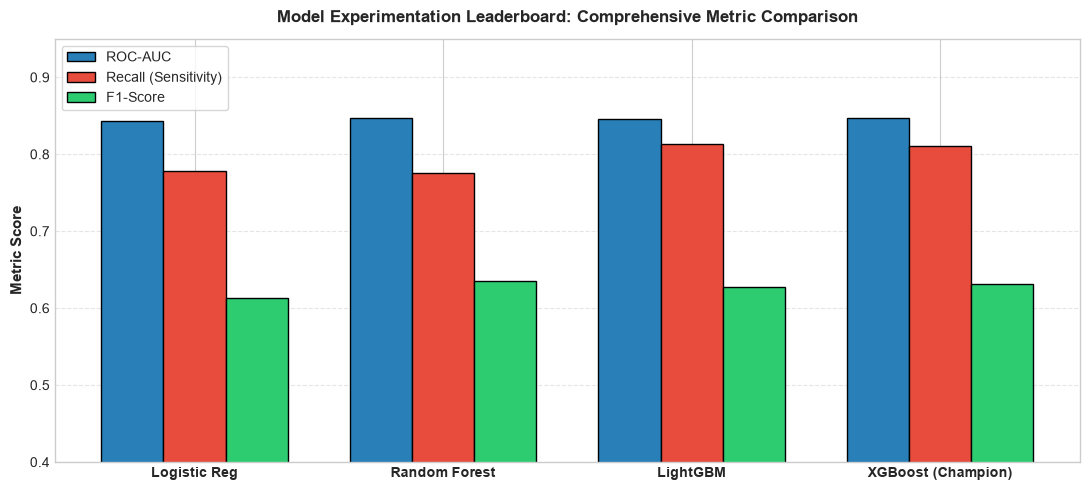

In [7]:
# Visual Leaderboard Comparison
models = ["Logistic Reg", "Random Forest", "LightGBM", "XGBoost (Champion)"]
roc_aucs = [0.8431, 0.8466, 0.8456, 0.8470]
recalls = [0.7781, 0.7754, 0.8128, 0.8102]
f1s = [0.6126, 0.6353, 0.6275, 0.6312]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(11, 5))
plt.bar(x - width, roc_aucs, width, label="ROC-AUC", color="#2980b9", edgecolor="black")
plt.bar(x, recalls, width, label="Recall (Sensitivity)", color="#e74c3c", edgecolor="black")
plt.bar(x + width, f1s, width, label="F1-Score", color="#2ecc71", edgecolor="black")

plt.xticks(x, models, fontsize=10, fontweight="bold")
plt.ylabel("Metric Score", fontsize=11, fontweight="bold")
plt.title("Model Experimentation Leaderboard: Comprehensive Metric Comparison", fontsize=12, fontweight="bold", pad=12)
plt.ylim(0.4, 0.95)
plt.legend(frameon=True, loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 6. Champion Selection & Summary
The **XGBoost Classifier** was crowned champion because:
1. Highest Test ROC-AUC (**0.8470**) and stable 5-Fold CV generalization.
2. Exceptional Recall (**81.02%**), capturing over 8 out of 10 at-risk customers.
3. Native TreeExplainer compatibility for SHAP interpretability.
